In [ ]:
!pip install transformers

In [ ]:
from pathlib import Path
from PIL import Image
from transformers import pipeline
from zipfile import ZipFile
from google.colab import drive
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

**SANITY CHECK FX**

In [ ]:
# testing data setup
drive.mount("/content/drive")
test_dir = "/content/drive/MyDrive/Plant_Disease_Dataset/sanity_check.zip"
extract_path = "/content/DATASET"

with ZipFile(test_dir, "r") as zipObj:
  zipObj.extractall(extract_path)

print("testing data loaded successfully")

# Load Hugging Face model
clip = pipeline(
    "zero-shot-image-classification",
    model="openai/clip-vit-base-patch32",
    device=0
)

def SanityCheck(img_path, threshold=0.40):
  image = Image.open(img_path).convert("RGB")
  check = clip(image, candidate_labels=["leaf", "not_a_leaf"])
  prediction = check[0]["label"]

  leaf_score = next(
    r["score"] for r in check
    if r["label"] == labels[0]
  )

  if leaf_score >= threshold:
    return 0
  else:
    return 1

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
testing data loaded successfully


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

**TESTING**

Accuracy Score: 97.3 %
Confusion Matrix: 
 [[21  0]
 [ 1 15]]


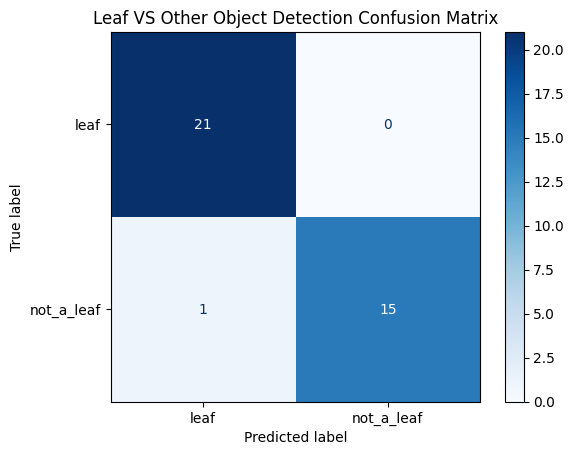

In [ ]:
# folder name
folder_name = "/content/DATASET/SANITY_CHECK"
labels = ["leaf", "not_a_leaf"]

# folder wise distribution [leaf, not_a_leaf]
def test_accuracy(folder, labels):

  y_pred = []
  y_test = []

  for category in labels:

    expected = 0 if category == "leaf" else 1

    image_paths = [
      p for p in Path(folder, category).rglob("*")
      if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    for path in image_paths:

      try:
        prediction = SanityCheck(path)

        # appending into evaluation arrays
        y_pred.append(prediction)
        y_test.append(expected)

      except Exception as e:
        print("Error:", path, e)

  if len(y_test) == 0:
    print("No images found!")
    return

  accuracy = accuracy_score(y_test, y_pred) * 100
  cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

  print("Accuracy Score:", round(accuracy, 2), "%")
  print("Confusion Matrix: \n", cm)

  display = ConfusionMatrixDisplay(cm, display_labels=labels)
  display.plot(cmap="Blues", values_format="d")
  plt.title("Leaf VS Other Object Detection Confusion Matrix")
  plt.show()

# testing call
test_accuracy(folder_name, labels)